In [ ]:
# ENGE707 Assessment 3 - Facial Feature Classification Challenge
### 8-class cat/dog eye, nose, mouth and face classification with transfer learning

This notebook is a complete, reproducible pipeline that covers every task in the brief. It is organised to mirror the marking rubric:

| Section | Brief task | Rubric criterion |
|---|---|---|
| 1 | Task 1 - Dataset exploration | Dataset Exploration and Understanding (5) |
| 2 | Task 2 - Preprocessing and pipeline | Data Preprocessing and Pipeline Preparation (10) |
| 3 | Task 3 - Model selection | Model Selection and Pipeline Development (20) |
| 4 | Task 4 - Training and over/underfitting | Training Strategy (15) |
| 5 | Task 5 - Evaluation and Kaggle submission | Model Evaluation and Kaggle Submission (15) |
| 6 | Task 6 - Analysis and improvements | Results Analysis and Improvement Strategies (10) |
| 7 | Task 7 - Reproducibility | Report Writing and Reproducibility (15) |

**How to run:** edit only the CONFIG cell, then Run All. A GPU is strongly recommended (Colab T4 or Kaggle GPU). Everything that is produced (figures, tables, `submission.csv`, `results.json`) is written to `outputs/` so it can be dropped straight into the report.

**Expected data layout** (auto-detected, see section 1.1):
```
<DATA_DIR>/
  train/            class sub-folders (CatEye/, DogEye/, ...)  OR  a flat folder of images + labels CSV
  test/             unlabelled test images
  train.csv         (optional) image id + label columns
  sample_submission.csv   (optional but recommended - the submission format is copied from it)
```

In [2]:
# %pip install -q scikit-learn pandas matplotlib pillow tqdm      # uncomment on a fresh machine (torch/torchvision are preinstalled on Colab/Kaggle)

## 0. Configuration

In [3]:
# ----------------------------- CONFIG: edit this cell only -----------------------------
DATA_DIR = "/kaggle/input/datasets/alyeid02/kaggle-comp"   # None = auto-detect
OUT_DIR = "outputs"

SEED = 42
IMG_SIZE = 160             # model input size (square)
BATCH_SIZE = 64
N_SPLITS = 6               # stratified-group split: 1/6 of the data (~16.7 %) is held out for validation

FINAL_ARCH = "convnext_tiny"   # one of: convnext_tiny | resnet50 | efficientnet_b0 | simple_cnn
FINAL_EPOCHS = 8
PATIENCE = 5               # early-stopping patience (epochs) on validation loss
WARMUP_EPOCHS = 1          # linear LR warm-up before cosine decay
LR_BACKBONE = 1e-4         # pretrained layers (small LR = gentle fine-tuning)
LR_HEAD = 1e-3             # newly initialised classification head
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
DROPOUT = 0.3
USE_CLASS_WEIGHTS = False  # switch on if section 1 shows a clear class imbalance

RUN_ABLATIONS = False      # train extra, shorter runs for the experiment-comparison table (section 6)
ABL_EPOCHS = 8

# Submission id style: "sample" = copy ids exactly as in sample_submission.csv (default, safest);
#                       "pad5" = 00001 | "plain" = 1.  Use only if Kaggle rejects the default.
ID_STYLE = "sample"

KAGGLE_USERNAME = "alyeid02"
KAGGLE_PUBLIC_SCORE = None  # type your leaderboard score here after submitting, then re-run section 5.4
# ---------------------------------------------------------------------------------------

In [4]:
import os, sys, json, math, random, hashlib, time, copy, platform, warnings, subprocess
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **k: x
warnings.filterwarnings("ignore")

OUT = Path(OUT_DIR); FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
seed_everything()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
print("Python", sys.version.split()[0], "|", platform.platform())

Python 3.13.15 | Linux-6.18.55+-x86_64-with-glibc2.39


## 1. Dataset exploration and understanding (Task 1)

**The problem.** Eight-class image classification. Each image is a close-up of one facial feature of a cat or a dog. The label is the combination of *species* (Cat, Dog) and *feature* (Eye, Nose, Mouth, Face). Two sources of confusion are therefore built in: species (a cat nose versus a dog nose) and feature (a mouth close-up versus a whole face).

### 1.1 Locate and load the data

In [5]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def autodetect():
    env = os.environ.get("DATA_DIR")
    cands = ([Path(env)] if env else []) + [Path.cwd(), Path.cwd() / "data", Path("/content/data"), Path("/content")]
    kin = Path("/kaggle/input")
    if kin.exists():
        cands += [p for p in kin.iterdir() if p.is_dir()]
    for c in cands:
        if c.is_dir() and any((c / n).is_dir() for n in ("test", "Test")):
            return c
    raise FileNotFoundError("Could not find a folder containing test/. Set DATA_DIR in the CONFIG cell.")

DATA = Path(DATA_DIR) if DATA_DIR else autodetect()

def list_images(d):
    return sorted(p for p in Path(d).rglob("*") if p.suffix.lower() in IMG_EXTS)
def find_dir(names):
    for n in names:
        if (DATA / n).is_dir(): return DATA / n
    return None

TRAIN_DIR = find_dir(["train", "Train", "training"])
TEST_DIR = find_dir(["test", "Test"])
csvs = list(DATA.glob("*.csv")) + (list(TRAIN_DIR.glob("*.csv")) if TRAIN_DIR else [])
SAMPLE_SUB = next((c for c in csvs if "sample" in c.name.lower() or "submission" in c.name.lower()), None)
LABELS_CSV = next((c for c in csvs if c != SAMPLE_SUB), None)
print("DATA        :", DATA)
print("train dir   :", TRAIN_DIR, "| test dir:", TEST_DIR)
print("labels csv  :", LABELS_CSV, "| sample submission:", SAMPLE_SUB)

def build_train_df():
    if TRAIN_DIR is None:
        raise FileNotFoundError("No train/ folder found under DATA_DIR.")
    imgs = list_images(TRAIN_DIR)
    if LABELS_CSV is not None:
        df = pd.read_csv(LABELS_CSV, dtype=str)      # dtype=str keeps zero-padded ids like "00012" intact
        id_col, lab_col = df.columns[0], df.columns[1]      # change here if your CSV has a different column order
        def key(v):                                   # "00001", "1" and "00001.jpg" all -> 1
            st = Path(str(v)).stem; return int(st) if st.isdigit() else st
        by_name = {p.name: p for p in imgs}; by_stem = {p.stem: p for p in imgs}; by_key = {key(p): p for p in imgs}
        resolve = lambda v: by_name.get(str(v)) or by_stem.get(Path(str(v)).stem) or by_key.get(key(v))
        df["path"] = df[id_col].map(resolve)
        miss = int(df["path"].isna().sum())
        if miss: print(f"WARNING: {miss} CSV rows have no matching image file and were dropped")
        df = df.dropna(subset=["path"]).rename(columns={lab_col: "label"})[["path", "label"]]
    else:
        df = pd.DataFrame({"path": imgs, "label": [p.parent.name for p in imgs]})   # folder-per-class layout
    df["path"] = df["path"].astype(str); df["label"] = df["label"].astype(str).str.strip()
    return df.reset_index(drop=True)

train_df = build_train_df()
test_paths = [str(p) for p in list_images(TEST_DIR)]
print(f"\nlabelled training images: {len(train_df):,} | unlabelled test images: {len(test_paths):,}")
train_df.head()

DATA        : /kaggle/input/datasets/alyeid02/kaggle-comp
train dir   : /kaggle/input/datasets/alyeid02/kaggle-comp/train | test dir: /kaggle/input/datasets/alyeid02/kaggle-comp/test
labels csv  : /kaggle/input/datasets/alyeid02/kaggle-comp/train_labels.csv | sample submission: /kaggle/input/datasets/alyeid02/kaggle-comp/sample_submission.csv

labelled training images: 63,660 | unlabelled test images: 29,443


,path,label
0,/kaggle/input/datasets/alyeid02/kaggle-comp/tr...,DogEye
1,/kaggle/input/datasets/alyeid02/kaggle-comp/tr...,DogMouth
2,/kaggle/input/datasets/alyeid02/kaggle-comp/tr...,DogFace
3,/kaggle/input/datasets/alyeid02/kaggle-comp/tr...,DogNose
4,/kaggle/input/datasets/alyeid02/kaggle-comp/tr...,DogNose


### 1.2 Class distribution and balance

,images,share_%
label,,
CatEye,13884,21.81
CatFace,6942,10.90
CatMouth,6942,10.90
CatNose,6942,10.90
DogEye,11580,18.19
DogFace,5790,9.10
DogMouth,5790,9.10
DogNose,5790,9.10


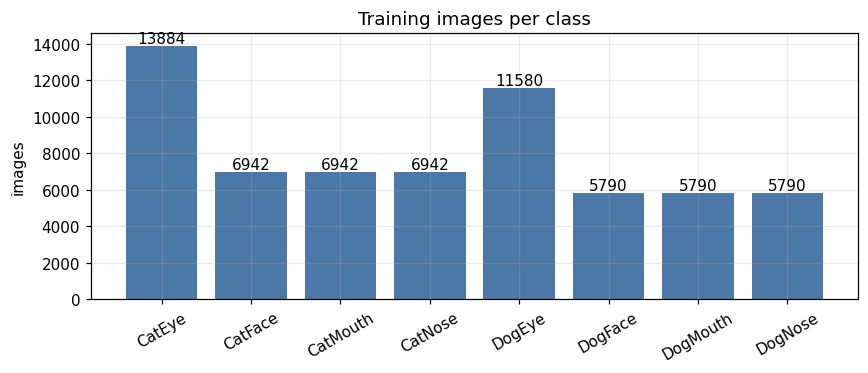

8 classes | largest/smallest = 2.40
Verdict: IMBALANCED (ratio >= 1.5) - consider class weights / macro-F1


In [6]:
counts = train_df["label"].value_counts().sort_index()
ratio = counts.max() / counts.min()
display(pd.DataFrame({"images": counts, "share_%": (100 * counts / counts.sum()).round(2)}))
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(counts.index, counts.values, color="#4C78A8")
ax.bar_label(bars); ax.set_ylabel("images"); ax.set_title("Training images per class"); plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig(FIG / "class_distribution.png"); plt.show()
print(f"{len(counts)} classes | largest/smallest = {ratio:.2f}")
print("Verdict:", "approximately balanced (ratio < 1.5)" if ratio < 1.5 else "IMBALANCED (ratio >= 1.5) - consider class weights / macro-F1")
assert len(counts) == 8, f"Expected 8 classes, found {len(counts)}: {list(counts.index)}"

### 1.3 Sample images from every class

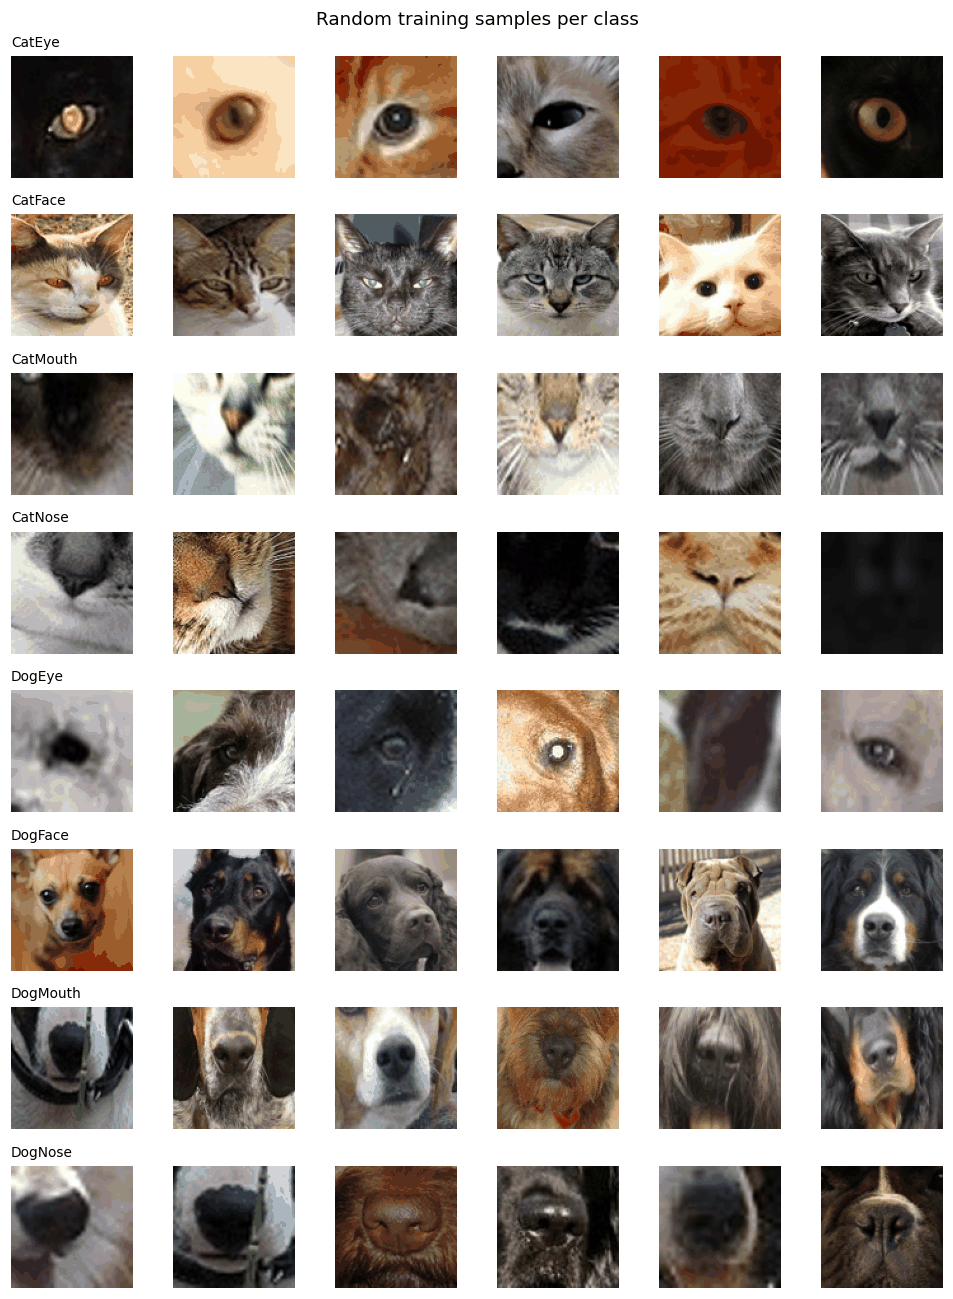

In [7]:
def show_grid(df, per_class=6, size=96, title="", fname=None):
    classes = sorted(df["label"].unique())
    fig, axes = plt.subplots(len(classes), per_class, figsize=(per_class * 1.5, len(classes) * 1.5))
    rng = np.random.RandomState(SEED)
    for r, c in enumerate(classes):
        sub = df[df["label"] == c]
        pick = sub.sample(min(per_class, len(sub)), random_state=rng)["path"].tolist()
        for k in range(per_class):
            ax = axes[r, k]; ax.axis("off")
            if k < len(pick):
                ax.imshow(Image.open(pick[k]).convert("RGB").resize((size, size)))
            if k == 0: ax.set_title(c, fontsize=9, loc="left")
    fig.suptitle(title); plt.tight_layout()
    if fname: plt.savefig(FIG / fname)
    plt.show()
show_grid(train_df, title="Random training samples per class", fname="samples_per_class.png")

### 1.4 Data-quality audit (one pass over train and test)
Checks: unreadable files, size and aspect-ratio variation, blur (variance of the Laplacian), exact duplicates (MD5), near duplicates (difference hash), label conflicts among duplicates, and train/test overlap. Results are cached so re-runs are fast.

In [8]:
def dhash(im, n=8):
    g = np.asarray(im.convert("L").resize((n + 1, n), Image.BILINEAR), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return format(int("".join("1" if b else "0" for b in bits), 2), "016x")

def lap_var(im):
    g = np.asarray(im.convert("L").resize((64, 64), Image.BILINEAR), dtype=np.float32)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    return float(lap.var())

def scan_one(p):
    try:
        with open(p, "rb") as f: md5 = hashlib.md5(f.read()).hexdigest()
        with Image.open(p) as im:
            im.load(); im = im.convert("RGB")
            return dict(path=str(p), ok=True, w=im.width, h=im.height, md5=md5, dhash=dhash(im), blur=lap_var(im))
    except Exception as e:
        return dict(path=str(p), ok=False, err=str(e)[:80])

def scan(paths, name):
    cache = OUT / f"scan_{name}.csv"
    if cache.exists():
        c = pd.read_csv(cache, dtype={"dhash": str})
        if set(c["path"]) == set(map(str, paths)): return c
    res = pd.DataFrame([scan_one(p) for p in tqdm(paths, desc=f"scan {name}")])
    res.to_csv(cache, index=False); return res

tr_scan = scan(train_df["path"].tolist(), "train")
te_scan = scan(test_paths, "test")
for nm, s in (("train", tr_scan), ("test", te_scan)):
    print(f"{nm}: {len(s):,} files | unreadable: {int((~s.ok).sum())}")
bad = tr_scan[~tr_scan.ok]
if len(bad): display(bad.head())
tr_scan = tr_scan[tr_scan.ok].copy(); te_scan = te_scan[te_scan.ok].copy()
train_df = train_df[train_df.path.isin(tr_scan.path)].merge(tr_scan[["path", "w", "h", "md5", "dhash", "blur"]], on="path").reset_index(drop=True)

scan train:   0%|          | 0/63660 [00:00<?, ?it/s]

scan test:   0%|          | 0/29443 [00:00<?, ?it/s]

train: 63,660 files | unreadable: 0
test: 29,443 files | unreadable: 0


,train,test
min w,4.0,8.0
median w,84.0,82.0
max w,2219.0,1832.0
min h,4.0,9.0
median h,80.0,80.0
max h,2219.0,1978.0
% non-square (|AR-1|>0.05),29.9,55.1
% shorter side < 64px,37.2,40.4
% shorter side < 32px,6.5,8.2
% longer side >= 512px,1.3,1.4


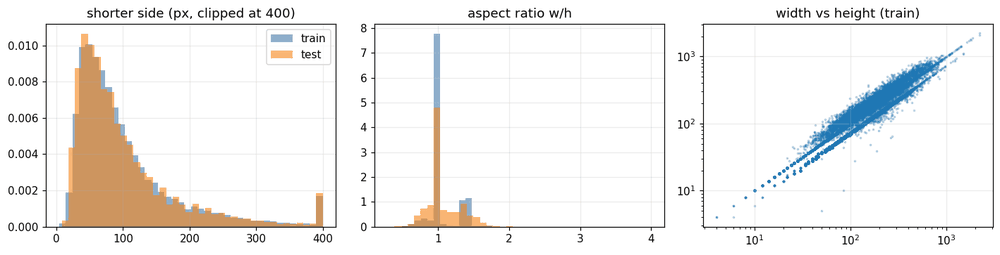

,count,mean,50%,min,max
label,,,,,
CatEye,13884.0,78.9,68.0,4.0,340.0
CatFace,6942.0,208.5,178.0,22.0,945.0
CatMouth,6942.0,93.4,80.0,4.0,394.0
CatNose,6942.0,78.7,68.0,4.0,340.0
DogEye,11580.0,75.3,62.0,14.0,886.0
DogFace,5790.0,189.7,155.0,39.0,2219.0
DogMouth,5790.0,93.8,77.0,17.0,1107.0
DogNose,5790.0,75.3,62.0,14.0,886.0


In [9]:
# ---- image sizes and aspect ratios (train versus test: checks for distribution shift) ----
for s in (tr_scan, te_scan): s["ar"] = s.w / s.h
summ = pd.DataFrame({
    n: {"min w": s.w.min(), "median w": s.w.median(), "max w": s.w.max(),
        "min h": s.h.min(), "median h": s.h.median(), "max h": s.h.max(),
        "% non-square (|AR-1|>0.05)": round(100 * ((s.ar - 1).abs() > .05).mean(), 1),
        "% shorter side < 64px": round(100 * (np.minimum(s.w, s.h) < 64).mean(), 1),
        "% shorter side < 32px": round(100 * (np.minimum(s.w, s.h) < 32).mean(), 1),
        "% longer side >= 512px": round(100 * (np.maximum(s.w, s.h) >= 512).mean(), 1)}
    for n, s in (("train", tr_scan), ("test", te_scan))})
display(summ)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for n, s, c in (("train", tr_scan, "#4C78A8"), ("test", te_scan, "#F58518")):
    ax[0].hist(np.minimum(s.w, s.h).clip(upper=400), bins=40, alpha=.6, label=n, color=c, density=True)
    ax[1].hist(s.ar.clip(.25, 4), bins=40, alpha=.6, label=n, color=c, density=True)
ax[0].set_title("shorter side (px, clipped at 400)"); ax[1].set_title("aspect ratio w/h"); ax[0].legend()
ax[2].scatter(tr_scan.w, tr_scan.h, s=2, alpha=.25); ax[2].set_title("width vs height (train)"); ax[2].set_xscale("log"); ax[2].set_yscale("log")
plt.tight_layout(); plt.savefig(FIG / "image_sizes.png"); plt.show()

# does size leak the label? (a model must not rely on image dimensions)
tmp = train_df.assign(short=np.minimum(train_df.w, train_df.h))
display(tmp.groupby("label")["short"].describe()[["count", "mean", "50%", "min", "max"]].round(1))

Laplacian-variance blur score: median 490; bottom 5 % below 48


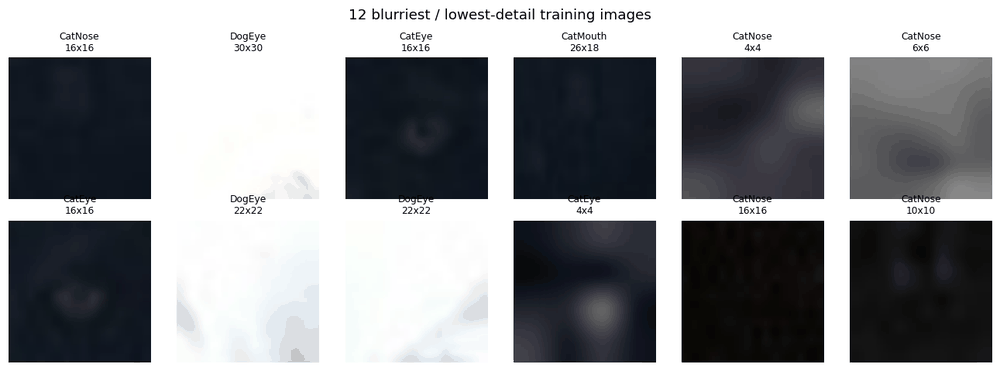

exact duplicate groups in train: 15 (30 images)
duplicate groups with CONFLICTING labels: 0
near-duplicate (identical dHash, different bytes) images in train: 64
train/test exact overlap: 0 identical files
duplicate pairs inside the test set: 124 images


In [10]:
# ---- blur ----
thr = tr_scan.blur.quantile(.05)
print(f"Laplacian-variance blur score: median {tr_scan.blur.median():.0f}; bottom 5 % below {thr:.0f}")
lowest = train_df.nsmallest(12, "blur")
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, (_, r) in zip(axes.ravel(), lowest.iterrows()):
    ax.imshow(Image.open(r.path).convert("RGB").resize((96, 96))); ax.axis("off"); ax.set_title(f"{r.label}\n{r.w}x{r.h}", fontsize=8)
plt.suptitle("12 blurriest / lowest-detail training images"); plt.tight_layout(); plt.savefig(FIG / "blurry_samples.png"); plt.show()

# ---- duplicates, label conflicts, train/test overlap ----
g = train_df.groupby("md5")
dup_groups = g.filter(lambda x: len(x) > 1)
conflict = g["label"].nunique(); conflict = conflict[conflict > 1]
print(f"exact duplicate groups in train: {dup_groups.md5.nunique()} ({len(dup_groups)} images)")
print(f"duplicate groups with CONFLICTING labels: {len(conflict)}")
near = train_df.groupby("dhash").filter(lambda x: len(x) > 1 and x.md5.nunique() > 1)
print(f"near-duplicate (identical dHash, different bytes) images in train: {len(near)}")
overlap = set(train_df.md5) & set(te_scan.md5)
print(f"train/test exact overlap: {len(overlap)} identical files")
print(f"duplicate pairs inside the test set: {int(te_scan.md5.duplicated(keep=False).sum())} images")
if len(conflict): display(train_df[train_df.md5.isin(conflict.index)].sort_values("md5")[["path", "label", "md5"]].head(10))

### 1.5 How the data will be used
* **Train (labelled)** -> split once into **training** and **validation** (stratified by class, grouped by file hash so duplicates cannot straddle the split; section 2.2). The validation set is used for early stopping, model selection and all reported metrics.
* **Test (unlabelled)** -> used once, at the very end, to produce `submission.csv`. Test images are never used for fitting, normalisation statistics, or tuning, and no labels are inferred from them.

## 2. Data preprocessing and pipeline preparation (Task 2)

### 2.1 Label encoding

In [11]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold
le = LabelEncoder().fit(train_df["label"])
CLASSES = list(le.classes_); NUM_CLASSES = len(CLASSES)
train_df["y"] = le.transform(train_df["label"])
print({c: int(i) for i, c in enumerate(CLASSES)})

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}


### 2.2 Train / validation split (stratified, group-aware, fixed seed)
`StratifiedGroupKFold` keeps class proportions the same in both parts and puts every set of byte-identical files (same MD5) on the same side of the split. That prevents optimistic validation scores caused by duplicate leakage.

In [12]:
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(train_df, train_df["y"], groups=train_df["md5"]))
tr_df, va_df = train_df.iloc[tr_idx].reset_index(drop=True), train_df.iloc[va_idx].reset_index(drop=True)

# leakage guards (hard failures)
assert set(tr_df.path).isdisjoint(va_df.path), "path leakage"
assert set(tr_df.md5).isdisjoint(va_df.md5), "duplicate-content leakage"
assert set(va_df.md5).isdisjoint(te_scan.md5) and set(tr_df.md5).isdisjoint(te_scan.md5), "train/test identical files"
print(f"train {len(tr_df):,} | validation {len(va_df):,} ({100*len(va_df)/len(train_df):.1f} %)")
display(pd.DataFrame({"train_%": 100 * tr_df.label.value_counts(normalize=True), "val_%": 100 * va_df.label.value_counts(normalize=True)}).round(2).sort_index())
tr_df.to_csv(OUT / "split_train.csv", index=False); va_df.to_csv(OUT / "split_val.csv", index=False)

train 53,051 | validation 10,609 (16.7 %)


,train_%,val_%
label,,
CatEye,21.75,22.13
CatFace,10.98,10.54
CatMouth,10.86,11.15
CatNose,10.91,10.90
DogEye,18.20,18.13
DogFace,9.10,9.09
DogMouth,9.04,9.36
DogNose,9.17,8.71


In [13]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models, transforms as T
from torchvision.transforms import functional as TF
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU - training will be slow")

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda | Tesla T4


### 2.3 Transforms and augmentation
**Shared (train, validation, test): centre-crop to a square (`SQUARE_MODE = "crop"`) -> `Resize` -> `ToTensor` -> `Normalize(ImageNet mean/std)`.**
Image shapes vary from under 10 px to nearly 2000 px and more than half of the test images are non-square. A shape analysis in section 1 found that in the training set the aspect ratio almost determines the class: every Mouth image is wide, nearly every tall image is a Face, and Eye and Nose images are square. The test set does not follow this pattern, so a model that can see the original shape learns a shortcut that does not transfer (validation 99.75% but leaderboard 92.0% with edge padding, which leaves the aspect ratio visible). Centre-cropping to a square hides the original aspect ratio, so the model must classify from the content. Normalisation uses the fixed ImageNet statistics that the pretrained backbone expects (no statistics are computed from validation or test data, so there is no leakage).

**Training only:** random-resized crop (scale 0.6-1), horizontal flip, +/-15 degree rotation, colour jitter, a **random down-then-up-sample** that imitates the many tiny, blurry images, Gaussian blur and random erasing. No vertical flip: upside-down faces do not occur in the data.

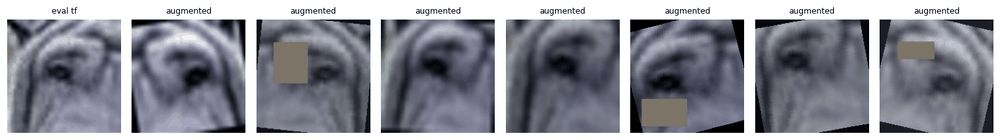

same eval transform is used for validation AND test -> True


In [14]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

# SQUARE_MODE decides how a non-square image becomes square.
#   "crop": centre-crop to a square (training uses a small random shift). The original aspect ratio is NOT visible to the model.
#   "pad" : edge-pad to a square. This keeps all pixels but leaves the aspect ratio visible as a padded band.
# Section 1 showed that in the training set aspect ratio almost determines the class (every Mouth image is wide, nearly every
# tall image is a Face, Eye and Nose images are square), but the test set does not follow that pattern. "crop" removes the shortcut.
SQUARE_MODE = "crop"

class PadToSquare:
    def __call__(self, img):
        w, h = img.size; s = max(w, h); l, t = (s - w) // 2, (s - h) // 2
        return TF.pad(img, [l, t, s - w - l, s - h - t], padding_mode="edge")

class CropToSquare:
    def __init__(self, jitter=0.0): self.jitter = jitter          # jitter = max shift as a fraction of the spare length
    def __call__(self, img):
        w, h = img.size; s = min(w, h); l, t = (w - s) // 2, (h - s) // 2
        if self.jitter:
            l += int(random.uniform(-self.jitter, self.jitter) * (w - s) / 2)
            t += int(random.uniform(-self.jitter, self.jitter) * (h - s) / 2)
        return img.crop((l, t, l + s, t + s))

make_sq = (lambda train: CropToSquare(0.5 if train else 0.0)) if SQUARE_MODE == "crop" else (lambda train: PadToSquare())

class RandomDownUp:   # mimic the very low-resolution images present in the data
    def __init__(self, p=.3, lo=24): self.p, self.lo = p, lo
    def __call__(self, img):
        if random.random() > self.p: return img
        s = img.size[0]; k = random.randint(self.lo, max(self.lo + 1, s // 2))
        return img.resize((k, k), Image.BILINEAR).resize((s, s), Image.BICUBIC)

eval_tf = T.Compose([make_sq(False), T.Resize((IMG_SIZE, IMG_SIZE), interpolation=T.InterpolationMode.BICUBIC, antialias=True),
                     T.ToTensor(), T.Normalize(MEAN, STD)])
train_tf = T.Compose([make_sq(True),
                      T.RandomResizedCrop(IMG_SIZE, scale=(.6, 1.), ratio=(.85, 1.18), interpolation=T.InterpolationMode.BICUBIC, antialias=True),
                      T.RandomHorizontalFlip(), T.RandomRotation(15),
                      T.ColorJitter(.3, .3, .2, .02), RandomDownUp(.3),
                      T.RandomApply([T.GaussianBlur(5, (.1, 1.5))], p=.2),
                      T.ToTensor(), T.Normalize(MEAN, STD), T.RandomErasing(p=.2, scale=(.02, .12))])
noaug_tf = eval_tf   # used by the "no augmentation" ablation

class ImgDS(Dataset):
    def __init__(self, paths, labels, tf):
        self.paths, self.labels, self.tf = list(paths), list(labels), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), int(self.labels[i])

def seed_worker(wid):
    s = torch.initial_seed() % 2**32; np.random.seed(s); random.seed(s)

def make_loaders(use_aug=True):
    nw = min(4, os.cpu_count() or 1); gen = torch.Generator().manual_seed(SEED)
    kw = dict(num_workers=nw, pin_memory=use_amp, worker_init_fn=seed_worker, persistent_workers=nw > 0)
    tl = DataLoader(ImgDS(tr_df.path, tr_df.y, train_tf if use_aug else noaug_tf), BATCH_SIZE, shuffle=True, drop_last=True, generator=gen, **kw)
    vl = DataLoader(ImgDS(va_df.path, va_df.y, eval_tf), BATCH_SIZE * 2, shuffle=False, **kw)
    return tl, vl

# visual check: one image under augmentation versus the deterministic evaluation transform
inv = lambda t: (t * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()
ex = Image.open(tr_df.path[0]).convert("RGB")
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
axes[0].imshow(inv(eval_tf(ex))); axes[0].set_title("eval tf", fontsize=8)
for k in range(1, 8): axes[k].imshow(inv(train_tf(ex))); axes[k].set_title("augmented", fontsize=8)
for a in axes: a.axis("off")
plt.tight_layout(); plt.savefig(FIG / "augmentation_examples.png"); plt.show()
print("same eval transform is used for validation AND test ->", eval_tf is eval_tf)

## 3. Model selection and pipeline development (Task 3)

**Choice: transfer learning with ConvNeXt-Tiny (ImageNet-1k pretrained), fine-tuned end to end.**

* **Why transfer learning:** ImageNet features (edges, fur and skin textures, eye and snout shapes, many dog and cat categories) are directly relevant to this task, and the labelled set is small relative to a 28M-parameter network. Pretrained models are explicitly allowed; no external *datasets* are used for training.
* **Why ConvNeXt-Tiny:** a modern CNN (7x7 depth-wise convs, LayerNorm, GELU) that matches Swin-style transformers on ImageNet at the same cost, is robust to the small batch sizes we use, and has no data-hungry attention layers. ResNet-50, EfficientNet-B0 and a from-scratch CNN are provided as comparison models.
* **Head:** pooled 768-d feature -> Dropout(0.3) -> Linear(768, 8). Output = 8 logits; softmax is applied inside the loss (training) and at inference.
* **Loss:** cross-entropy with label smoothing 0.1 (reduces over-confidence, and helps when some labels are ambiguous, for example near-identical cat and dog noses).
* **Optimiser:** AdamW, weight decay 0.05 (not applied to biases/norm parameters). **Discriminative LRs:** 1e-4 for the pretrained body, 1e-3 for the new head. **Schedule:** 1 epoch linear warm-up then cosine decay. **Batch size** 64. **Epochs** up to 20 with early stopping.
* **Input:** 224x224x3.

In [15]:
class SimpleCNN(nn.Module):   # from-scratch baseline (used for comparison)
    def __init__(self, nc, dropout=.3):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                                            nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True), nn.MaxPool2d(2))
        self.features = nn.Sequential(blk(3, 32), blk(32, 64), blk(64, 128), blk(128, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(256, nc))
    def forward(self, x): return self.classifier(self.pool(self.features(x)))

def build_model(arch, nc, pretrained=True, dropout=DROPOUT):
    if arch == "simple_cnn":
        m = SimpleCNN(nc, dropout); return m, m.classifier
    spec = {"convnext_tiny": ("ConvNeXt_Tiny_Weights", "IMAGENET1K_V1"), "resnet50": ("ResNet50_Weights", "IMAGENET1K_V2"),
            "efficientnet_b0": ("EfficientNet_B0_Weights", "IMAGENET1K_V1")}[arch]
    try:
        m = getattr(models, arch)(weights=getattr(getattr(models, spec[0]), spec[1]) if pretrained else None)
    except Exception as e:
        print(f"!! could not load pretrained weights ({str(e)[:70]}). Enable internet access. Falling back to RANDOM init.")
        m = getattr(models, arch)(weights=None)
    if arch == "convnext_tiny":
        m.classifier[2] = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier[2].in_features, nc)); head = m.classifier[2]
    elif arch == "resnet50":
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, nc)); head = m.fc
    else:
        m.classifier[1] = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier[1].in_features, nc)); head = m.classifier[1]
    return m, head

m, h = build_model(FINAL_ARCH, NUM_CLASSES)
tot = sum(p.numel() for p in m.parameters()); trn = sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"{FINAL_ARCH}: {tot/1e6:.1f}M parameters ({trn/1e6:.1f}M trainable) | head: {h}")
with torch.no_grad(): print("dummy forward:", tuple(m.eval()(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE)).shape), "(batch, classes)")
del m, h

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 246MB/s] 


convnext_tiny: 27.8M parameters (27.8M trainable) | head: Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=768, out_features=8, bias=True)
)
dummy forward: (2, 8) (batch, classes)


## 4. Training strategy and over/underfitting management (Task 4)

Monitoring: per-epoch training and validation loss and accuracy (both computed with plain cross-entropy so the curves are comparable, even though the optimiser uses label smoothing).
Generalisation controls used: **transfer learning, data augmentation, dropout, weight decay, label smoothing, gradient clipping, LR warm-up + cosine decay, early stopping with best-checkpoint restore.**
After training, the code reports the train-validation gap and flags likely over- or underfitting from the curves; the interpretation of *why* belongs in the report.

In [16]:
def make_optimizer(model, head, lr_backbone, lr_head, wd):
    head_ids = {id(p) for p in head.parameters()}; groups = []
    for is_head, lr in ((False, lr_backbone), (True, lr_head)):
        decay, nodecay = [], []
        for _, p in model.named_parameters():
            if not p.requires_grad or (id(p) in head_ids) != is_head: continue
            (nodecay if p.ndim <= 1 else decay).append(p)
        groups += [dict(params=decay, lr=lr, weight_decay=wd), dict(params=nodecay, lr=lr, weight_decay=0.)]
    return torch.optim.AdamW([g for g in groups if g["params"]])

def run_epoch(model, loader, crit=None, opt=None, sched=None, scaler=None):
    train = opt is not None; model.train(train)
    tl = tc = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
            out = out.float()
            if train:
                loss = crit(out, y); opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
            tl += F.cross_entropy(out.detach(), y, reduction="sum").item()
            tc += (out.argmax(1) == y).sum().item(); n += len(y)
    return tl / n, tc / n

def fit(model, head, tl, vl, epochs, lr_backbone, lr_head, name, class_weights=None):
    model.to(device)
    cw = torch.tensor(class_weights, dtype=torch.float32, device=device) if class_weights is not None else None
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=LABEL_SMOOTHING)
    opt = make_optimizer(model, head, lr_backbone, lr_head, WEIGHT_DECAY)
    total, warm = epochs * len(tl), WARMUP_EPOCHS * len(tl)
    lam = lambda s: (s + 1) / warm if s < warm else .01 + .99 * .5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "lr")}
    best, best_ep, best_state, bad = float("inf"), 0, None, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        a, b = run_epoch(model, tl, crit, opt, sched, scaler); c, d = run_epoch(model, vl)
        for k, v in zip(hist, (a, b, c, d, opt.param_groups[-1]["lr"])): hist[k].append(v)
        flag = ""
        if c < best - 1e-4:
            best, best_ep, bad = c, ep, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}; flag = " *best"
        else: bad += 1
        print(f"[{name}] ep {ep:02d}/{epochs} train {a:.4f}/{b:.4f} | val {c:.4f}/{d:.4f} | {time.time()-t0:.0f}s{flag}")
        if bad >= PATIENCE: print(f"[{name}] early stopping at epoch {ep} (best epoch {best_ep})"); break
    model.load_state_dict(best_state)
    return hist, best_ep

def diagnose(h, best_ep):
    i = best_ep - 1; gap_acc = h["train_acc"][i] - h["val_acc"][i]; gap_loss = h["val_loss"][i] - h["train_loss"][i]
    print(f"best epoch {best_ep}: train acc {h['train_acc'][i]:.3f} | val acc {h['val_acc'][i]:.3f} | acc gap {gap_acc:+.3f} | loss gap {gap_loss:+.3f}")
    if h["train_acc"][i] < .80: print("-> signs of UNDERFITTING (low training accuracy): bigger model, longer training, weaker regularisation")
    if gap_acc > .08 or gap_loss > .25: print("-> signs of OVERFITTING (large train/val gap): stronger augmentation/regularisation, more data, early stop sooner")
    if len(h["val_loss"]) - best_ep >= 2 and h["val_loss"][-1] > h["val_loss"][i] + .02:
        print("-> validation loss rose after the best epoch (overfitting onset) - early stopping restored the best weights")
    if gap_acc <= .08 and gap_loss <= .25 and h["train_acc"][i] >= .80: print("-> no strong over/underfitting signal: good fit")

def plot_curves(h, name, best_ep):
    ep = range(1, len(h["val_loss"]) + 1); fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].plot(ep, h["train_loss"], "o-", label="train"); ax[0].plot(ep, h["val_loss"], "o-", label="validation"); ax[0].set_title("Loss (cross-entropy)")
    ax[1].plot(ep, h["train_acc"], "o-", label="train"); ax[1].plot(ep, h["val_acc"], "o-", label="validation"); ax[1].set_title("Accuracy")
    ax[2].plot(ep, h["lr"], "o-", color="gray"); ax[2].set_title("Learning rate (head)"); ax[2].set_yscale("log")
    for a in ax[:2]: a.axvline(best_ep, ls="--", c="k", alpha=.5, label=f"best epoch {best_ep}"); a.set_xlabel("epoch"); a.legend()
    plt.suptitle(name); plt.tight_layout(); plt.savefig(FIG / f"curves_{name}.png"); plt.show()

### 4.1 Train the final model


=== final_convnext_tiny: arch=convnext_tiny aug=True pretrained=True epochs=8 ===
[final_convnext_tiny] ep 01/8 train 0.5841/0.7941 | val 0.2668/0.9145 | 178s *best
[final_convnext_tiny] ep 02/8 train 0.2966/0.9070 | val 0.2505/0.9141 | 158s *best
[final_convnext_tiny] ep 03/8 train 0.2713/0.9182 | val 0.2366/0.9322 | 156s *best
[final_convnext_tiny] ep 04/8 train 0.2551/0.9237 | val 0.2308/0.9348 | 156s *best
[final_convnext_tiny] ep 05/8 train 0.2360/0.9351 | val 0.2362/0.9285 | 156s
[final_convnext_tiny] ep 06/8 train 0.2283/0.9383 | val 0.2283/0.9314 | 156s *best
[final_convnext_tiny] ep 07/8 train 0.2176/0.9431 | val 0.2243/0.9348 | 155s *best
[final_convnext_tiny] ep 08/8 train 0.2146/0.9447 | val 0.2239/0.9357 | 156s *best


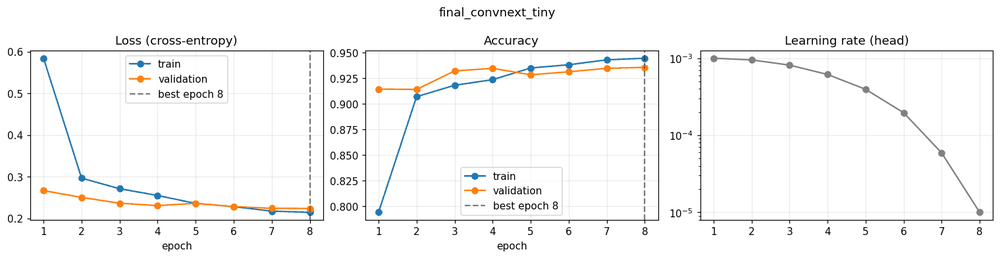

best epoch 8: train acc 0.945 | val acc 0.936 | acc gap +0.009 | loss gap +0.009
-> no strong over/underfitting signal: good fit
[final_convnext_tiny] VAL acc 0.9357 | loss 0.2239 | macro-F1 0.9231


In [17]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, log_loss)

@torch.no_grad()
def predict_probs(model, loader, tta=False):
    model.eval().to(device); out = []
    for x, _ in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            p = model(x).float().softmax(1)
            if tta: p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2   # horizontal-flip TTA
        out.append(p.cpu())
    return torch.cat(out).numpy()

def class_weights_from(df):
    c = np.bincount(df.y, minlength=NUM_CLASSES); return len(df) / (NUM_CLASSES * c)

def run_experiment(name, arch, use_aug=True, pretrained=True, epochs=FINAL_EPOCHS, lr_backbone=LR_BACKBONE, lr_head=LR_HEAD, keep_model=False):
    print(f"\n=== {name}: arch={arch} aug={use_aug} pretrained={pretrained} epochs={epochs} ===")
    seed_everything(); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    tl, vl = make_loaders(use_aug)
    model, head = build_model(arch, NUM_CLASSES, pretrained)
    t0 = time.time()
    hist, best_ep = fit(model, head, tl, vl, epochs, lr_backbone, lr_head, name, class_weights_from(tr_df) if USE_CLASS_WEIGHTS else None)
    probs = predict_probs(model, vl); y = va_df.y.values; pred = probs.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    res = dict(name=name, arch=arch, augmentation=use_aug, pretrained=pretrained, best_epoch=best_ep, epochs_run=len(hist["val_loss"]),
               val_acc=accuracy_score(y, pred), val_loss=log_loss(y, probs, labels=list(range(NUM_CLASSES))),
               macro_precision=p, macro_recall=r, macro_f1=f1, train_acc_at_best=hist["train_acc"][best_ep - 1],
               minutes=(time.time() - t0) / 60, history=hist)
    plot_curves(hist, name, best_ep); diagnose(hist, best_ep)
    print(f"[{name}] VAL acc {res['val_acc']:.4f} | loss {res['val_loss']:.4f} | macro-F1 {res['macro_f1']:.4f}")
    if keep_model:
        torch.save(model.state_dict(), OUT / f"{name}_best.pt"); res["model"] = model
    else:
        del model; torch.cuda.empty_cache()
    return res

RESULTS = {}
RESULTS["final"] = run_experiment("final_" + FINAL_ARCH, FINAL_ARCH, use_aug=True, keep_model=True)
final_model = RESULTS["final"].pop("model")

## 5. Model evaluation and Kaggle submission (Task 5)

### 5.1 Validation metrics

In [18]:
y_val = va_df.y.values
val_probs = predict_probs(final_model, make_loaders(False)[1])
val_probs_tta = predict_probs(final_model, make_loaders(False)[1], tta=True)
pred = val_probs.argmax(1)
print(f"Validation accuracy        : {accuracy_score(y_val, pred):.4f}")
print(f"Validation accuracy (+TTA) : {accuracy_score(y_val, val_probs_tta.argmax(1)):.4f}")
print(f"Validation loss (plain CE) : {log_loss(y_val, val_probs, labels=list(range(NUM_CLASSES))):.4f}\n")
print(classification_report(y_val, pred, target_names=CLASSES, digits=4))
rep = pd.DataFrame(classification_report(y_val, pred, target_names=CLASSES, output_dict=True, digits=4)).T
rep.to_csv(OUT / "classification_report.csv")

Validation accuracy        : 0.9357
Validation accuracy (+TTA) : 0.9351
Validation loss (plain CE) : 0.2239

              precision    recall  f1-score   support

      CatEye     0.9991    0.9974    0.9983      2348
     CatFace     0.9991    1.0000    0.9996      1118
    CatMouth     0.6729    0.9358    0.7829      1183
     CatNose     0.8868    0.5355    0.6677      1156
      DogEye     0.9979    0.9990    0.9984      1923
     DogFace     0.9969    0.9990    0.9979       964
    DogMouth     0.9534    0.9889    0.9708       993
     DogNose     0.9921    0.9470    0.9690       924

    accuracy                         0.9357     10609
   macro avg     0.9373    0.9253    0.9231     10609
weighted avg     0.9452    0.9357    0.9333     10609



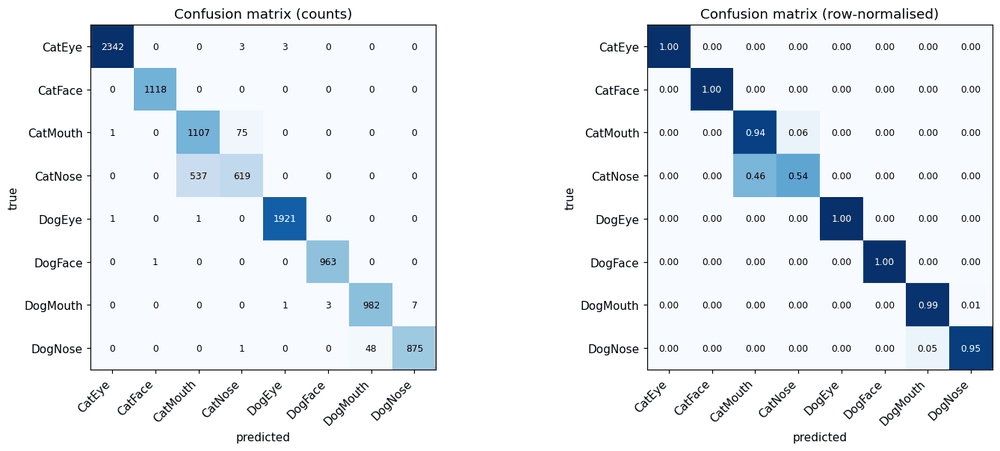

,per-class accuracy (recall)
CatNose,0.5355
CatMouth,0.9358
DogNose,0.9470
DogMouth,0.9889
CatEye,0.9974
DogEye,0.9990
DogFace,0.9990
CatFace,1.0000


In [19]:
cm = confusion_matrix(y_val, pred, labels=range(NUM_CLASSES)); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6))
for a, M, t, fmt in ((ax[0], cm, "Confusion matrix (counts)", "d"), (ax[1], cmn, "Confusion matrix (row-normalised)", ".2f")):
    im = a.imshow(M, cmap="Blues"); a.set_title(t); a.set_xticks(range(NUM_CLASSES)); a.set_yticks(range(NUM_CLASSES))
    a.set_xticklabels(CLASSES, rotation=45, ha="right"); a.set_yticklabels(CLASSES); a.grid(False)
    a.set_xlabel("predicted"); a.set_ylabel("true")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            a.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=8, color="white" if M[i, j] > M.max() * .55 else "black")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png"); plt.show()
pc = pd.Series(np.diag(cmn), index=CLASSES, name="per-class accuracy (recall)").sort_values(); display(pc.round(4).to_frame())

### 5.2 Where do the errors come from? (species versus feature)
Because the label is *species x feature*, every mistake is one of three kinds: right feature / wrong species, right species / wrong feature, or both wrong.

In [20]:
import re
def split_name(c):
    m = re.match(r"^(Cat|Dog)(.+)$", c, re.I); return (m.group(1).title(), m.group(2).title()) if m else (None, None)
parts = [split_name(c) for c in CLASSES]
if all(s is not None for s, _ in parts):
    sp = np.array([s for s, _ in parts]); ft = np.array([f for _, f in parts])
    wrong = pred != y_val; t, p_ = y_val[wrong], pred[wrong]
    same_feat = (ft[t] == ft[p_]); same_sp = (sp[t] == sp[p_])
    kinds = pd.Series({"right feature, wrong species": int((same_feat & ~same_sp).sum()),
                       "right species, wrong feature": int((~same_feat & same_sp).sum()),
                       "both wrong": int((~same_feat & ~same_sp).sum())})
    display(pd.DataFrame({"errors": kinds, "% of errors": (100 * kinds / max(1, kinds.sum())).round(1)}))
    print(f"Species accuracy only: {np.mean(sp[y_val] == sp[pred]):.4f} | feature accuracy only: {np.mean(ft[y_val] == ft[pred]):.4f}")
    sp_by_feat = pd.DataFrame({"feature": ft[y_val], "species_correct": sp[y_val] == sp[pred]}).groupby("feature").species_correct.mean().round(4)
    display(sp_by_feat.to_frame("cat-vs-dog accuracy by feature"))
else:
    print("class names do not follow the <Cat|Dog><Feature> pattern - skipping species/feature breakdown")

,errors,% of errors
"right feature, wrong species",6,0.9
"right species, wrong feature",675,99.0
both wrong,1,0.1


Species accuracy only: 0.9993 | feature accuracy only: 0.9363


,cat-vs-dog accuracy by feature
feature,
Eye,0.9988
Face,0.9995
Mouth,1.0000
Nose,0.9995


### 5.3 Predict the Kaggle test set and write `submission.csv`
The ID and label format is copied from `sample_submission.csv` (same row order, same ID style, class name or integer index according to that file). Ids are matched numerically, so `1`, `00001` and `00001.jpg` all refer to the same test image; the class-name spelling is checked against the sample file. Test-time augmentation (horizontal flip) is used for the final predictions.

In [21]:
test_loader = DataLoader(ImgDS(test_paths, [-1] * len(test_paths), eval_tf), BATCH_SIZE * 2, shuffle=False, num_workers=min(4, os.cpu_count() or 1))
test_probs = predict_probs(final_model, test_loader, tta=True); test_pred = test_probs.argmax(1)
np.save(OUT / "test_probs.npy", test_probs)

def id_key(v):                       # "00001", "1" and "00001.jpg" all map to the same key (1)
    st = Path(str(v)).stem
    return int(st) if st.isdigit() else st
test_key = {id_key(p): i for i, p in enumerate(test_paths)}
assert len(test_key) == len(test_paths), "test filenames are not unique after id normalisation"
if SAMPLE_SUB is not None:
    ss = pd.read_csv(SAMPLE_SUB, dtype=str); id_col, lab_col = ss.columns[0], ss.columns[1]   # str keeps ids like "00012" intact
    is_num = bool(ss[lab_col].str.fullmatch(r"-?\d+").all())          # integer-coded labels in the sample file?
    missing = [v for v in ss[id_col] if id_key(v) not in test_key]
    assert not missing, f"{len(missing)} ids in sample_submission have no test image, e.g. {missing[:3]}"
    assert len(ss) == len(test_paths) and ss[id_col].map(id_key).is_unique, "sample_submission and test folder do not cover the same ids"
    rows = [test_key[id_key(v)] for v in ss[id_col]]
    labs = test_pred[rows]
    if ID_STYLE == "pad5": ids = [str(id_key(v)).zfill(5) for v in ss[id_col]]
    elif ID_STYLE == "plain": ids = [str(id_key(v)) for v in ss[id_col]]
    else: ids = ss[id_col].tolist()
    sub = pd.DataFrame({id_col: ids, lab_col: labs if is_num else le.inverse_transform(labs)})
    for c in ss.columns[2:]: sub[c] = ss[c]
    # class-name guard: the labels we write must be spelled exactly like the sample file's (e.g. DogEye vs DogEyes)
    if not is_num and ss[lab_col].nunique() >= NUM_CLASSES:
        unknown = set(sub[lab_col]) - set(ss[lab_col])
        assert not unknown, f"class names {unknown} do not appear in sample_submission ({sorted(ss[lab_col].unique())}). Rename train labels or map them."
else:
    print("WARNING: no sample_submission.csv found - writing id=filename, label=class name. Check this against the Kaggle Data tab!")
    sub = pd.DataFrame({"image_id": [Path(p).stem for p in test_paths], "class": le.inverse_transform(test_pred)})
assert len(sub) == len(ss if SAMPLE_SUB is not None else test_paths) and not sub.isna().any().any()
sub.to_csv(OUT / "submission.csv", index=False)
print(sub.head(), "\n", f"\nwrote {OUT/'submission.csv'} ({len(sub):,} rows)")
print("predicted class distribution on test:"); display(sub.iloc[:, 1].value_counts(normalize=True).round(4).to_frame("share"))

  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth 
 
wrote outputs/submission.csv (29,443 rows)
predicted class distribution on test:


,share
class,
CatEye,0.2151
DogEye,0.1888
CatMouth,0.1423
CatFace,0.1066
DogMouth,0.1017
DogFace,0.0961
DogNose,0.0840
CatNose,0.0654


### 5.4 Kaggle leaderboard versus validation
Submit `outputs/submission.csv` on the competition **Submit Predictions** page, **screenshot the leaderboard row showing your username and score**, then type the score into `KAGGLE_PUBLIC_SCORE` in the CONFIG cell and re-run this cell. Compare the two numbers in the report: a validation score that is much higher than the leaderboard score suggests leakage or a validation/test distribution mismatch; the two being close supports the split strategy.

In [22]:
val_acc = accuracy_score(y_val, val_probs_tta.argmax(1))
print(f"Kaggle username : {KAGGLE_USERNAME}")
print(f"Validation acc  : {val_acc:.4f}  (with TTA, same inference as the submission)")
if KAGGLE_PUBLIC_SCORE is None:
    print("Kaggle score    : not entered yet - submit, then set KAGGLE_PUBLIC_SCORE")
else:
    d = val_acc - KAGGLE_PUBLIC_SCORE
    print(f"Kaggle score    : {KAGGLE_PUBLIC_SCORE:.4f}\nvalidation - leaderboard = {d:+.4f}",
          "-> consistent" if abs(d) < .02 else "-> investigate: possible validation/test mismatch or leakage")

Kaggle username : alyeid02
Validation acc  : 0.9351  (with TTA, same inference as the submission)
Kaggle score    : not entered yet - submit, then set KAGGLE_PUBLIC_SCORE


## 6. Results analysis and improvement strategies (Task 6)

### 6.1 Confident mistakes
The most confidently wrong predictions are the most informative: they are either genuine model failures (for example heavy blur, or a feature that is partly out of frame) or **label noise / ambiguous classes**.

682 misclassified of 10609 validation images (6.43 %)


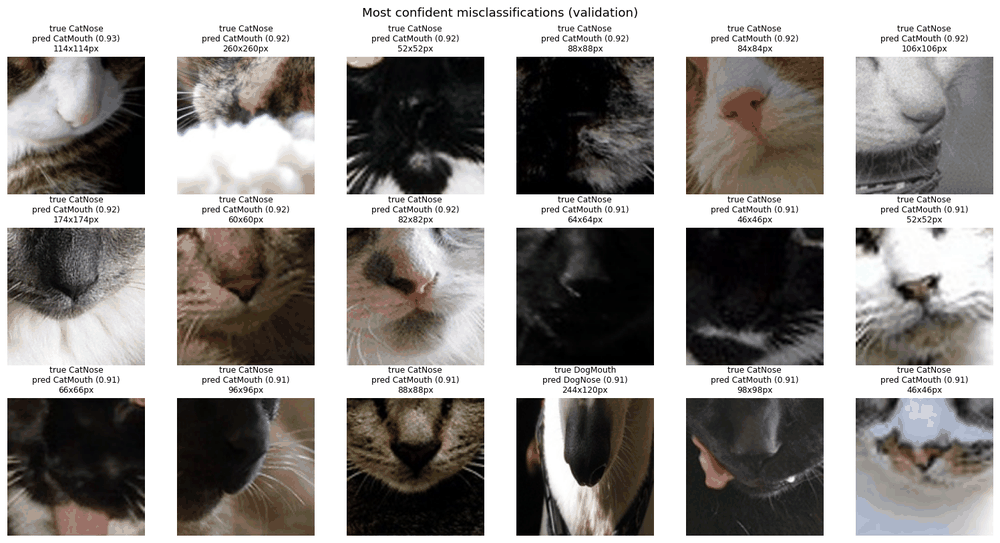

,true,predicted,count
0,CatNose,CatMouth,537
1,CatMouth,CatNose,75
2,DogNose,DogMouth,48
3,DogMouth,DogNose,7
4,CatEye,CatNose,3
5,CatEye,DogEye,3
6,DogMouth,DogFace,3
7,CatMouth,CatEye,1
8,DogEye,CatEye,1
9,DogEye,CatMouth,1


,error rate,count
res_bin,,
<32,0.0897,892
32-64,0.0702,3219
64-128,0.0723,3972
128-256,0.0436,1926
>256,0.0083,600


,error rate,count
blur_bin,,
blurriest 25%,0.0890,2653
Q2,0.0716,2652
Q3,0.0547,2652
sharpest 25%,0.0419,2652


In [23]:
wrong_idx = np.where(pred != y_val)[0]
conf = val_probs[wrong_idx, pred[wrong_idx]]; order = wrong_idx[np.argsort(-conf)][:18]
print(f"{len(wrong_idx)} misclassified of {len(y_val)} validation images ({100*len(wrong_idx)/len(y_val):.2f} %)")
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for ax, i in zip(axes.ravel(), order):
    r = va_df.iloc[i]; ax.imshow(Image.open(r.path).convert("RGB").resize((128, 128))); ax.axis("off")
    ax.set_title(f"true {CLASSES[y_val[i]]}\npred {CLASSES[pred[i]]} ({val_probs[i, pred[i]]:.2f})\n{r.w}x{r.h}px", fontsize=8)
plt.suptitle("Most confident misclassifications (validation)"); plt.tight_layout(); plt.savefig(FIG / "confident_errors.png"); plt.show()

pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
display(pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:10], columns=["true", "predicted", "count"]))

# error rate versus image resolution and blur: does low quality drive the errors?
va_an = va_df.assign(err=(pred != y_val), short=np.minimum(va_df.w, va_df.h))
va_an["res_bin"] = pd.cut(va_an.short, [0, 32, 64, 128, 256, 1e5], labels=["<32", "32-64", "64-128", "128-256", ">256"])
va_an["blur_bin"] = pd.qcut(va_an.blur, 4, labels=["blurriest 25%", "Q2", "Q3", "sharpest 25%"])
display(va_an.groupby("res_bin").err.agg(["mean", "count"]).rename(columns={"mean": "error rate"}).round(4))
display(va_an.groupby("blur_bin").err.agg(["mean", "count"]).rename(columns={"mean": "error rate"}).round(4))

### 6.2 Experiment comparison (preprocessing, augmentation, model choice)
Shorter runs of alternative settings under the **same split and seed**: no augmentation, a from-scratch CNN, and two other pretrained backbones. These provide the evidence for the "effectiveness of augmentation, model choice and training strategy" discussion.

,name,arch,augmentation,pretrained,epochs_run,best_epoch,train_acc_at_best,val_acc,val_loss,macro_f1,minutes
0,final_convnext_tiny,convnext_tiny,True,True,8,8,0.9447,0.9357,0.2239,0.9231,21.3679


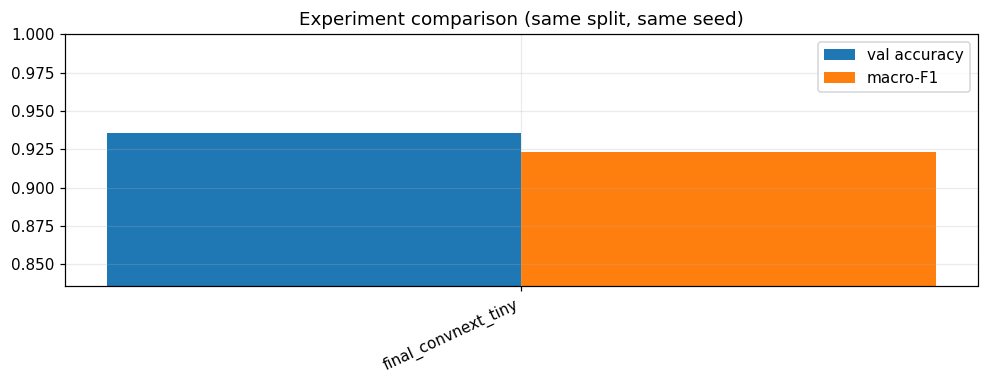

In [24]:
if RUN_ABLATIONS:
    del final_model; torch.cuda.empty_cache(); final_model = None
    RESULTS["final_short"] = run_experiment(f"{FINAL_ARCH}_aug_short", FINAL_ARCH, True, True, ABL_EPOCHS)
    RESULTS["noaug"] = run_experiment(f"{FINAL_ARCH}_no_aug", FINAL_ARCH, False, True, ABL_EPOCHS)
    RESULTS["scratch"] = run_experiment("simple_cnn_scratch_aug", "simple_cnn", True, False, ABL_EPOCHS, lr_backbone=1e-3, lr_head=1e-3)
    for a in [a for a in ("resnet50", "efficientnet_b0") if a != FINAL_ARCH]:
        RESULTS[a] = run_experiment(f"{a}_aug", a, True, True, ABL_EPOCHS)
    final_model = build_model(FINAL_ARCH, NUM_CLASSES, False)[0]
    final_model.load_state_dict(torch.load(OUT / f"final_{FINAL_ARCH}_best.pt", map_location="cpu"))   # restore the final model
cols = ["name", "arch", "augmentation", "pretrained", "epochs_run", "best_epoch", "train_acc_at_best", "val_acc", "val_loss", "macro_f1", "minutes"]
comp = pd.DataFrame([{k: v for k, v in r.items() if k in cols} for r in RESULTS.values()])[cols].round(4)
display(comp); comp.to_csv(OUT / "experiment_comparison.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 3.6)); x = np.arange(len(comp)); w = .38
ax.bar(x - w/2, comp.val_acc, w, label="val accuracy"); ax.bar(x + w/2, comp.macro_f1, w, label="macro-F1")
ax.set_xticks(x); ax.set_xticklabels(comp.name, rotation=25, ha="right"); ax.set_ylim(max(0, comp.val_acc.min() - .1), 1); ax.legend(); ax.set_title("Experiment comparison (same split, same seed)")
plt.tight_layout(); plt.savefig(FIG / "experiment_comparison.png"); plt.show()

### 6.3 Improvement strategies to evaluate (for the written discussion)
Judged from the evidence above (the confusion pairs, the resolution/blur breakdown and the experiment table), realistic next steps include:
1. **Ensembling** the fine-tuned ConvNeXt with a ResNet/EfficientNet (the errors of different architectures are rarely identical) and averaging softmax probabilities.
2. **K-fold cross-validation** (the group-aware split is already in place) for a more reliable estimate and a fold ensemble for the test set.
3. **Higher-resolution inputs or a larger backbone** if errors concentrate on fine texture, with the caveat that many source images are under 64 px, so extra resolution cannot add real information.
4. **Stronger or learned augmentation** (RandAugment, MixUp/CutMix) if the train-validation gap is large; **longer training** if training accuracy is low.
5. **Label audit** of the confident-error list above and of any conflicting duplicates, then relabel or remove noisy items.
6. **Class-weighted loss or re-sampling** if the confusion matrix shows weak recall for a minority class.
7. **Layer-wise learning-rate decay / gradual unfreezing** and **hyper-parameter search** (learning rate, weight decay, label smoothing).

**Strengths:** reproducible and leakage-safe, domain-specific augmentation, calibrated by label smoothing, error analysis built in. **Weaknesses:** a single validation split, no ensembling, resolution limited by the data, and ablation runs shorter than the final run (so the comparison is indicative rather than exact).

## 7. Reproducibility record (Task 7)
Writes `results.json` (configuration, metrics, library versions, hardware, git commit) and a frozen `requirements_frozen.txt`.

In [25]:
def git_hash():
    try: return subprocess.check_output(["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL).decode().strip()
    except Exception: return None
record = dict(
    kaggle_username=KAGGLE_USERNAME, kaggle_public_score=KAGGLE_PUBLIC_SCORE, classes=CLASSES,
    config={k: globals()[k] for k in ("SEED", "IMG_SIZE", "BATCH_SIZE", "N_SPLITS", "FINAL_ARCH", "FINAL_EPOCHS", "PATIENCE", "WARMUP_EPOCHS",
                                      "LR_BACKBONE", "LR_HEAD", "WEIGHT_DECAY", "LABEL_SMOOTHING", "DROPOUT", "USE_CLASS_WEIGHTS", "ABL_EPOCHS")},
    data=dict(train_images=len(train_df), train_split=len(tr_df), val_split=len(va_df), test_images=len(test_paths)),
    final=dict(**{k: v for k, v in RESULTS["final"].items() if k != "history"}), history=RESULTS["final"]["history"],
    experiments=[{k: v for k, v in r.items() if k != "history"} for r in RESULTS.values()],
    environment=dict(python=sys.version.split()[0], torch=torch.__version__, torchvision=torchvision.__version__, numpy=np.__version__,
                     pandas=pd.__version__, platform=platform.platform(), device=str(device),
                     gpu=torch.cuda.get_device_name(0) if device.type == "cuda" else None),
    git_commit=git_hash())
json.dump(record, open(OUT / "results.json", "w"), indent=2, default=float)
try:
    open(OUT / "requirements_frozen.txt", "w").write(subprocess.check_output([sys.executable, "-m", "pip", "freeze"]).decode())
except Exception as e: print("pip freeze failed:", e)
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

saved:
  classification_report.csv
  experiment_comparison.csv
  figures
  final_convnext_tiny_best.pt
  requirements_frozen.txt
  results.json
  scan_test.csv
  scan_train.csv
  split_train.csv
  split_val.csv
  submission.csv
  test_probs.npy


In [26]:
import shutil, os
from IPython.display import FileLink, display
src = "/kaggle/working/outputs"
print(sorted(os.listdir(src)))
shutil.copy(src + "/submission.csv", "/kaggle/working/submission.csv")
shutil.make_archive("/kaggle/working/outputs_bundle", "zip", src)
display(FileLink("submission.csv"))
display(FileLink("outputs_bundle.zip"))

['classification_report.csv', 'experiment_comparison.csv', 'figures', 'final_convnext_tiny_best.pt', 'requirements_frozen.txt', 'results.json', 'scan_test.csv', 'scan_train.csv', 'split_train.csv', 'split_val.csv', 'submission.csv', 'test_probs.npy']


/kaggle/working/submission.csv

/kaggle/working/outputs_bundle.zip

### Submission checklist
- [ ] Report, 3,000-3,500 words, with Turnitin similarity report (<= 20 %)
- [ ] This notebook, run top to bottom, outputs visible
- [ ] `outputs/submission.csv` (final Kaggle submission file)
- [ ] Kaggle username + **leaderboard screenshot**
- [ ] GitHub repository link and commit history (>= 2 meaningful commits per week)
- [ ] All libraries, pretrained models and papers referenced (e.g. Liu et al. 2022 *A ConvNet for the 2020s*; He et al. 2016; Loshchilov and Hutter 2019 *AdamW*; PyTorch/torchvision; scikit-learn)